# 02 · Exploratory Data Analysis
ภาพรวมยอดขาย พฤติกรรมการซื้อ หมวดสินค้า และโปรโมชัน — ยืนยันตัวเลขในสไลด์ Preliminary EDA และขยายเพิ่ม

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config
from src.viz import setup, save, seg_palette, PRIMARY, ACCENT, MUTED
setup()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.width", 160)

In [2]:
from src.data import load, load_transactions_clean
tx = load_transactions_clean()
baskets = tx.groupby(["household_key", "BASKET_ID"]).agg(
    DAY=("DAY", "first"), WEEK_NO=("WEEK_NO", "first"), hour=("hour", "first"),
    sales=("SALES_VALUE", "sum"), items=("QUANTITY", "size"))
hh = tx.groupby("household_key").SALES_VALUE.sum().sort_values(ascending=False)

## 1. KPI ภาพรวม

In [3]:
weekly = tx.groupby("WEEK_NO").SALES_VALUE.sum()
kpi = pd.Series({
    "Total sales (2 yrs)": f"${tx.SALES_VALUE.sum():,.0f}",
    "Households": f"{tx.household_key.nunique():,}",
    "Baskets": f"{len(baskets):,}",
    "Avg basket value": f"${baskets.sales.mean():,.2f}",
    "Median basket value": f"${baskets.sales.median():,.2f}",
    "Avg spend per household": f"${hh.mean():,.0f}",
    "Avg baskets per household": f"{len(baskets) / tx.household_key.nunique():,.0f}",
    "Avg weekly sales (weeks 17-102)": f"${weekly.loc[17:].mean():,.0f}",
})
kpi.to_frame("value")

,value
Total sales (2 yrs),"$8,057,444"
Households,"2,500"
Baskets,"275,539"
Avg basket value,$29.24
Median basket value,$17.18
Avg spend per household,"$3,223"
Avg baskets per household,110
Avg weekly sales (weeks 17-102),"$86,711"


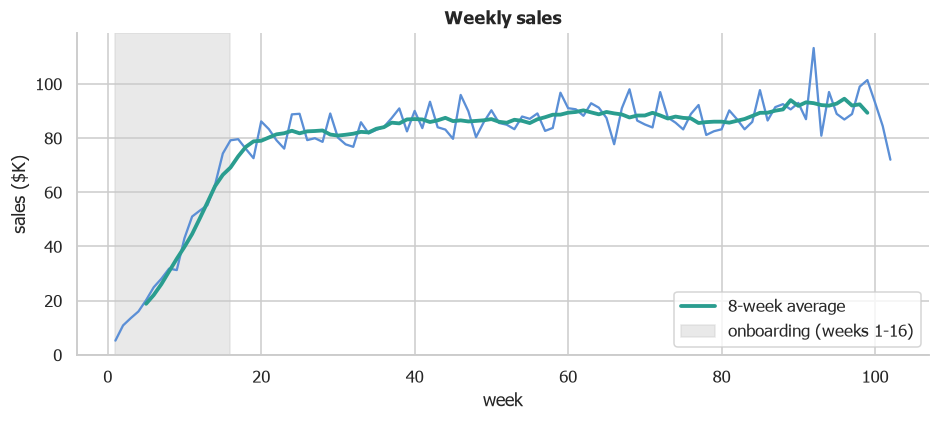

avg weekly sales  weeks 17-59: $84,259  ·  weeks 60-102: $89,162  ·  change +5.8%


In [4]:
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(weekly.index, weekly.values / 1e3, color=PRIMARY)
ax.plot(weekly.index, weekly.rolling(8, center=True).mean() / 1e3, color=ACCENT, lw=2.5, label="8-week average")
ax.axvspan(1, 16, color=MUTED, alpha=.4, label="onboarding (weeks 1-16)")
ax.set(title="Weekly sales", xlabel="week", ylabel="sales ($K)")
ax.legend(loc="lower right")
save(fig, "02_weekly_sales")
plt.show()

h1, h2 = weekly.loc[17:59].mean(), weekly.loc[60:102].mean()
print(f"avg weekly sales  weeks 17-59: ${h1:,.0f}  ·  weeks 60-102: ${h2:,.0f}  ·  change {h2 / h1 - 1:+.1%}")

**ผล:** หลังช่วง onboarding ยอดขายเฉลี่ย **~$87K/สัปดาห์** และโตเพียง **~6%** ระหว่างครึ่งแรกกับครึ่งหลัง
(ไม่ถึง 3% ต่อปี) — โตช้า และ notebook 03 จะแสดงว่าการเติบโตมาจากบางกลุ่ม ขณะที่อีกกลุ่มกำลังหดตัว

## 2. Pareto — ลูกค้ากลุ่มเล็กทำยอดขายส่วนใหญ่

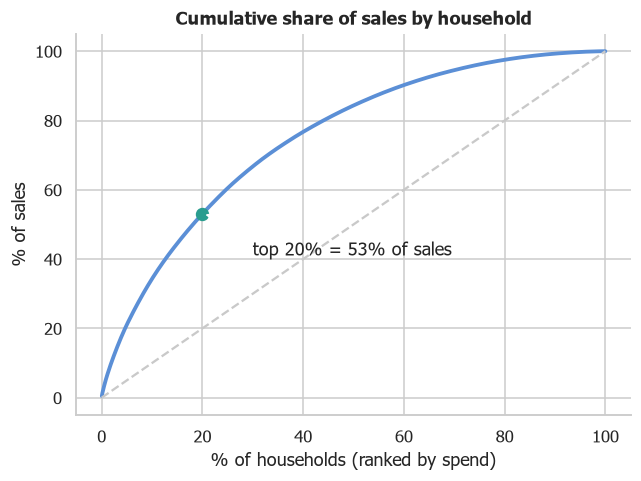

top 10% households -> 34.3% of sales
top 20% households -> 53.0% of sales
top 50% households -> 84.3% of sales


In [5]:
cum_share = hh.cumsum() / hh.sum()
pct_hh = np.arange(1, len(hh) + 1) / len(hh)
top20 = cum_share.iloc[int(len(hh) * .2) - 1]

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(pct_hh * 100, cum_share.values * 100, color=PRIMARY, lw=2.5)
ax.plot([0, 100], [0, 100], color=MUTED, ls="--")
ax.scatter([20], [top20 * 100], color=ACCENT, zorder=3, s=60)
ax.annotate(f"top 20% = {top20:.0%} of sales", (20, top20 * 100), (30, top20 * 100 - 12),
            arrowprops=dict(arrowstyle="->"))
ax.set(title="Cumulative share of sales by household", xlabel="% of households (ranked by spend)",
       ylabel="% of sales")
save(fig, "02_pareto")
plt.show()
for p in (.1, .2, .5):
    print(f"top {p:.0%} households -> {cum_share.iloc[int(len(hh) * p) - 1]:.1%} of sales")

## 3. หมวดสินค้าและแบรนด์

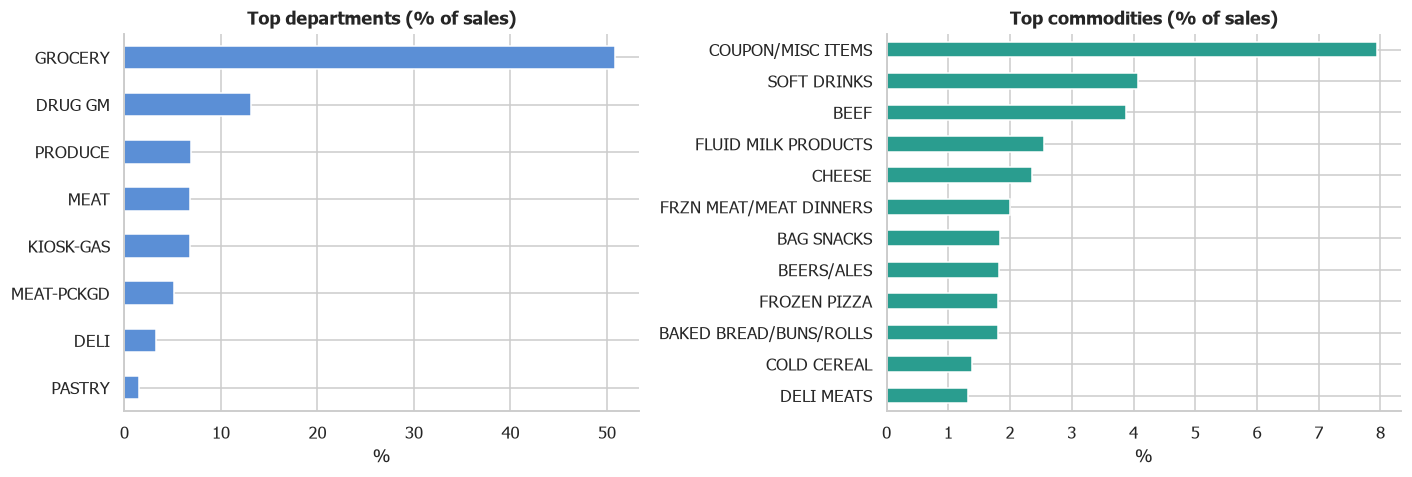

In [6]:
dept = (tx.groupby("DEPARTMENT").SALES_VALUE.sum() / tx.SALES_VALUE.sum()).sort_values(ascending=False)
comm = tx.groupby("COMMODITY_DESC").SALES_VALUE.sum().sort_values(ascending=False).head(12) / tx.SALES_VALUE.sum()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
dept.head(8).iloc[::-1].mul(100).plot.barh(ax=axes[0], color=PRIMARY)
axes[0].set(title="Top departments (% of sales)", xlabel="%", ylabel="")
comm.iloc[::-1].mul(100).plot.barh(ax=axes[1], color=ACCENT)
axes[1].set(title="Top commodities (% of sales)", xlabel="%", ylabel="")
plt.tight_layout()
save(fig, "02_categories")
plt.show()

In [7]:
brand = tx.groupby("BRAND").SALES_VALUE.sum() / tx.SALES_VALUE.sum()
print("Brand share of sales:"); print(brand.map("{:.1%}".format))

Brand share of sales:
BRAND
National    72.2%
Private     27.8%
Name: SALES_VALUE, dtype: str


**ผล:** GROCERY คือหมวดหลัก (~51%) ตามด้วย DRUG GM (~13%) · สินค้าแบรนด์ร้าน (Private) ~27% ของยอดขาย

## 4. ตะกร้าและช่วงเวลาซื้อ

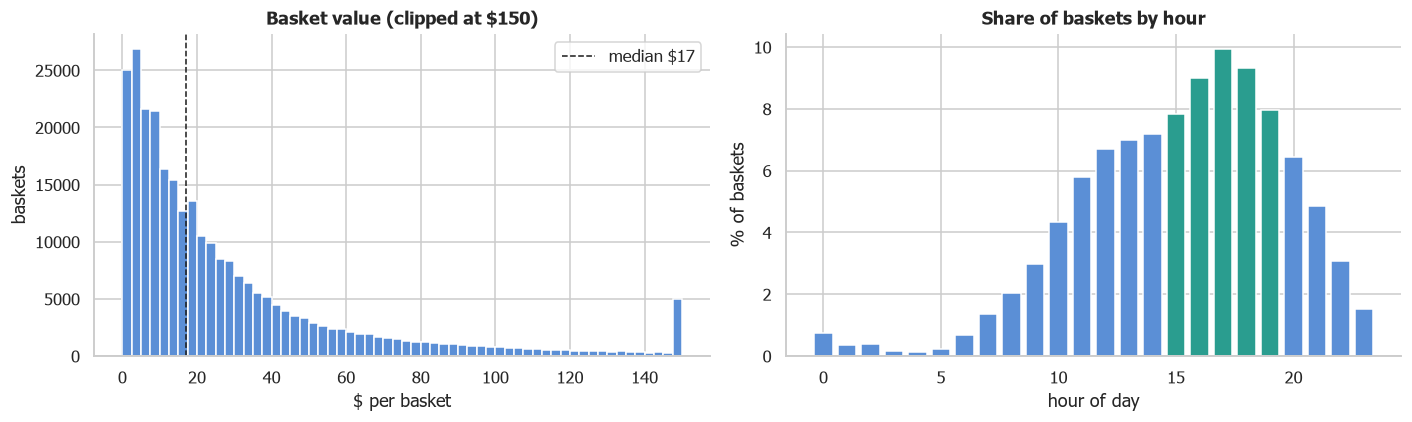

baskets 15:00-19:59: 44.0%
baskets under $10: 33.6% · median items per basket: 5


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(baskets.sales.clip(upper=150), bins=60, color=PRIMARY)
axes[0].axvline(baskets.sales.median(), color="k", ls="--", lw=1, label=f"median ${baskets.sales.median():.0f}")
axes[0].set(title="Basket value (clipped at $150)", xlabel="$ per basket", ylabel="baskets")
axes[0].legend()

by_hour = baskets.groupby("hour").size() / len(baskets) * 100
axes[1].bar(by_hour.index, by_hour.values, color=[ACCENT if 15 <= h <= 19 else PRIMARY for h in by_hour.index])
axes[1].set(title="Share of baskets by hour", xlabel="hour of day", ylabel="% of baskets")
plt.tight_layout()
save(fig, "02_basket_hour")
plt.show()
print(f"baskets 15:00-19:59: {baskets.hour.between(15, 19).mean():.1%}")
print(f"baskets under $10: {(baskets.sales < 10).mean():.1%} · median items per basket: {baskets['items'].median():.0f}")

**ผล:** ตะกร้าส่วนใหญ่มีมูลค่าเล็ก (median ต่ำกว่าค่าเฉลี่ยมาก — มีตะกร้าใหญ่ไม่กี่ใบดึงค่าเฉลี่ยขึ้น)
และช่วงพีคคือ **15:00–19:59** → โอกาสเพิ่มมูลค่าตะกร้าด้วยการขายคู่ (cross-sell)

## 5. โปรโมชันและคูปอง

In [9]:
promo = pd.Series({
    "items bought on retail discount": f"{tx.on_promo.mean():.1%}",
    "sales value on retail discount": f"{tx.loc[tx.on_promo, 'SALES_VALUE'].sum() / tx.SALES_VALUE.sum():.1%}",
    "total retail discount given": f"${tx.retail_disc.sum():,.0f}",
    "retail discount as % of (sales + discount)": f"{tx.retail_disc.sum() / (tx.SALES_VALUE.sum() + tx.retail_disc.sum()):.1%}",
    "items bought with a coupon": f"{tx.used_coupon.mean():.2%}",
    "total coupon discount": f"${tx.coupon_disc.sum():,.0f}",
    "sales value on retail discount, EXCLUDING fuel/misc": f"{tx.loc[~tx.is_non_merch & tx.on_promo, 'SALES_VALUE'].sum() / tx.loc[~tx.is_non_merch, 'SALES_VALUE'].sum():.1%}",
    "retail discount on fuel only": f"${tx.loc[tx.DEPARTMENT == 'KIOSK-GAS', 'retail_disc'].sum():,.0f}",
})
promo.to_frame("value")

,value
items bought on retail discount,50.4%
sales value on retail discount,50.3%
total retail discount given,"$1,383,619"
retail discount as % of (sales + discount),14.7%
items bought with a coupon,1.22%
total coupon discount,"$32,235"
"sales value on retail discount, EXCLUDING fuel/misc",47.2%
retail discount on fuel only,"$17,225"


**ผล:** ประมาณครึ่งหนึ่งของรายการถูกซื้อตอนมีส่วนลดหน้าร้าน รวมส่วนลด **$1.38M** (≈15% ของราคาเต็ม)
ถ้าไม่นับน้ำมัน (ลดราคาเกือบทุกรายการ แต่ส่วนลดรวมเพียง ~$17K) สัดส่วนยอดขายที่ขายตอนลดราคาคือ **~47%**
ขณะที่คูปองถูกใช้แค่ ~1% ของรายการ — ร้านพึ่ง **ลดราคาแบบเหมารวม** มากกว่าข้อเสนอเฉพาะคน

## 6. ข้อมูลประชากร (801 ครัวเรือน)
ตัวแปรถูกปิดชื่อ (`classification_1` น่าจะเป็นกลุ่มอายุ, `classification_3` เป็นระดับรายได้) จึงดูเฉพาะความสัมพันธ์กับยอดซื้อ

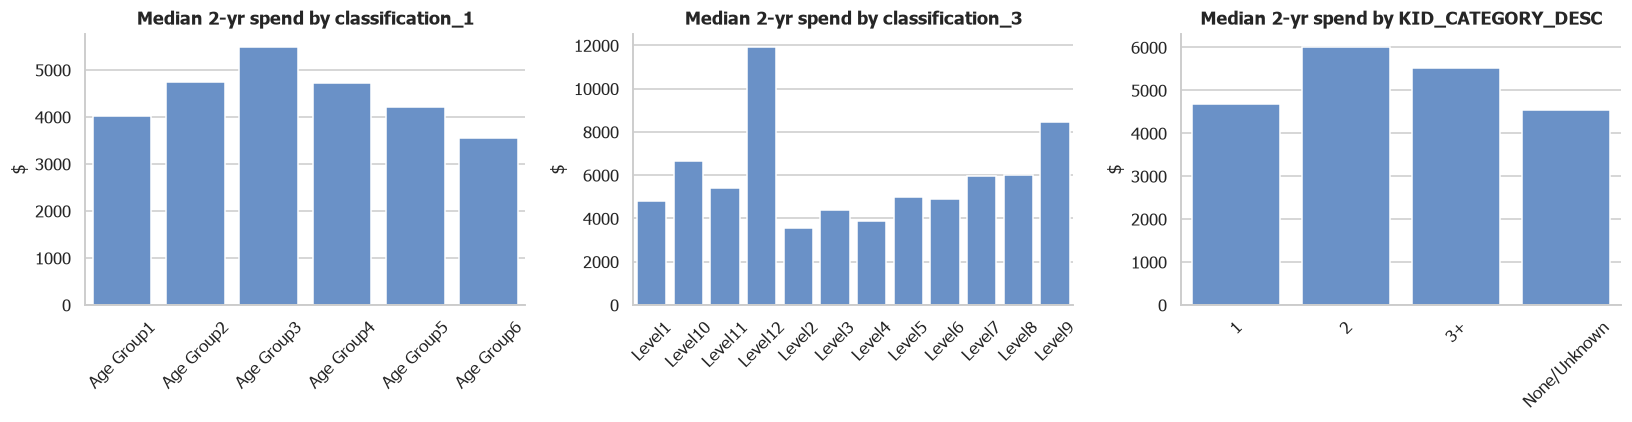

In [10]:
demo = load("hh_demographic").set_index("household_key").join(hh.rename("spend"), how="inner")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["classification_1", "classification_3", "KID_CATEGORY_DESC"]):
    order = sorted(demo[col].dropna().unique())
    sns.barplot(data=demo, x=col, y="spend", order=order, ax=ax, color=PRIMARY, errorbar=None, estimator="median")
    ax.set(title=f"Median 2-yr spend by {col}", xlabel="", ylabel="$")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
save(fig, "02_demographics")
plt.show()

## สรุป EDA
1. ยอดขาย **$8.06M ใน 2 ปี ~$87K/สัปดาห์** โตช้า (~6% ระหว่างครึ่งแรกกับครึ่งหลัง)
2. **ลูกค้า top 20% ทำยอดขาย ~53%** — เสียกลุ่มนี้ไปจะกระทบหนัก
3. **GROCERY ~51%** ของยอดขาย เป็นหมวดหลักสำหรับโปรและการขายคู่
4. ตะกร้าเล็ก (median ต่ำกว่าค่าเฉลี่ย) พีคช่วง 15–19 น.
5. **~47% ของยอดขาย (ไม่นับน้ำมัน) เกิดตอนลดราคา** แต่คูปองแทบไม่ถูกใช้ → ส่วนลดแบบหว่านเป็นต้นทุนหลัก